## 25W-COM SCI-M148 Project 2 - Binary Classification Comparative Methods

Name: Aashna Sibal

UID: [redacted]

### **Submission Guidelines**
1. Please fill in your name and UID above.

2. Please submit a **PDF printout** of your Jupyter Notebook to **Gradescope**. If you have any trouble accessing Gradescope, please let a TA know ASAP.  

3. As the PDF can get long, please tag the respective sections to ensure the readers know where to look.  

For this project we're going to attempt a binary classification of a dataset using multiple methods and compare results.

Our goals for this project will be to introduce you to several of the most common classification techniques, how to perform them and tweek parameters to optimize outcomes, how to produce and interpret results, and compare performance. You will be asked to analyze your findings and provide explanations for observed performance.

Specifically you will be asked to classify whether a <b>patient is suffering from heart disease</b> based on a host of potential medical factors.

<b><u>DEFINITIONS</b></u>


<b> Binary Classification:</b>
In this case a complex dataset has an added 'target' label with one of two options. Your learning algorithm will try to assign one of these labels to the data.

<b> Supervised Learning:</b>
This data is fully supervised, which means it's been fully labeled and we can trust the veracity of the labeling.

## Background: The Dataset

For this exercise, we will be using a subset of the <b>UCI Heart Disease dataset</b>. This dataset was created by collecting clinical data from patients undergoing diagnostic tests for heart disease. All identifying information about the patients has been removed to protect their privacy. The dataset represents data from patients who were suspected of having heart disease and underwent several diagnostic tests, including blood tests, electrocardiograms (ECG), exercise stress tests, and fluoroscopic imaging.

The dataset includes 14 columns. The information provided by each column is as follows:
<ul>
    <li><b>age:</b> Patient age in years</li>
    <li><b>sex:</b> Patient sex (1 = male; 0 = female)</li>
    <li><b>c_pain:</b> Chest pain type (0 = asymptomatic; 1 = atypical angina (unusual discomfort due to reduced blood flow to the heart); 2 = non-anginal pain (chest pain unrelated to the heart); 3 = typical angina (classic chest discomfort due to reduced blood flow to the heart))</li>
    <li><b>rbp:</b> Resting blood pressure in mm Hg (measured at hospital admission)</li>
    <li><b>chol:</b> Serum cholesterol level in mg/dL</li>
    <li><b>high_fbs:</b> Fasting blood sugar > 120 mg/dL (1 = true; 0 = false)</li>
    <li><b>r_ecg:</b> Resting electrocardiographic results (0 = probable thickened left ventricular wall; 1 = normal; 2 = ST-T wave abnormality)</li>
    <li><b>hr_max:</b> Maximum heart rate achieved during the stress test</li>
    <li><b>has_ex_ang:</b> Exercise-induced angina (1 = yes; 0 = no)</li>
    <li><b>ecg_depress:</b> Depression of the ST segment on ECG during exercise compared to rest (measured in mm)</li>
    <li><b>stress_slope:</b> Slope of the peak exercise ST segment (0 = downsloping (concerning); 1 = flat (abnormal); 2 = upsloping (normal))</li>
    <li><b>num_vessels:</b> Number of major vessels (0–3) showing good blood flow during fluoroscopy</li>
    <li><b>thal_test_res:</b> Thallium Stress Test result (assesses blood flow using trace amounts of radioactive thallium-201) (1 = normal; 2 = fixed defect; 7 = reversible defect)</li>
    <li><b>heart_disease:</b> Indicates whether heart disease is present (True = Disease; False = No disease)</li>
</ul>


## Loading Essentials and Helper Functions

In [124]:
#Here are a set of libraries we imported to complete this assignment.
#Feel free to use these or equivalent libraries for your implementation
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # this is used for the plot the graph
import os
import seaborn as sns # used for plot interactive graph.
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn import metrics
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
import sklearn.metrics.cluster as smc
from sklearn.model_selection import KFold


from matplotlib import pyplot
import itertools

%matplotlib inline

import random

random.seed(42)

## Part 1. Load the Data and Analyze

Let's first load our dataset so we'll be able to work with it. (correct the relative path if your notebook is in a different directory than the csv file.)

In [125]:
data = pd.read_csv('heartdisease.csv')

### Now that our data is loaded, let's take a closer look at the dataset we're working with. Use the head method,  the describe method, and the info method to display some of the rows so we can visualize the types of data fields we'll be working with.

In [126]:
data.head()

,age,sex,chest_pain,rpb,chol,high_fbs,r_ecg,hr_max,ex_ang,ecg_depress,stress_slope,num_vessels,thal_test_res,heart_disease
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,False
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,False
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,False
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,False
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,False


In [127]:
data.describe()

,age,sex,chest_pain,rpb,chol,high_fbs,r_ecg,hr_max,ex_ang,ecg_depress,stress_slope,num_vessels,thal_test_res
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000


In [128]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   age            303 non-null    int64  
 1   sex            303 non-null    int64  
 2   chest_pain     303 non-null    int64  
 3   rpb            303 non-null    int64  
 4   chol           303 non-null    int64  
 5   high_fbs       303 non-null    int64  
 6   r_ecg          303 non-null    int64  
 7   hr_max         303 non-null    int64  
 8   ex_ang         303 non-null    int64  
 9   ecg_depress    303 non-null    float64
 10  stress_slope   303 non-null    int64  
 11  num_vessels    303 non-null    int64  
 12  thal_test_res  303 non-null    int64  
 13  heart_disease  303 non-null    bool   
dtypes: bool(1), float64(1), int64(12)
memory usage: 31.2 KB


### Before we begin our analysis we need to fix the field(s) that will be problematic. Specifically convert our boolean heart_disease variable into a binary numeric target variable (values of either '0' or '1'), and then drop the original heart_disease datafield from the dataframe. (hint: try label encoder or .astype())

In [129]:
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()
data['heart_disease_binary'] = labelencoder.fit_transform(data['heart_disease'])
data = data.drop('heart_disease',axis=1)

### Now that we have a feel for the data-types for each of the variables, plot histograms of each field and attempt to ascertain how each variable performs (is it a binary, or limited selection, or does it follow a gradient?

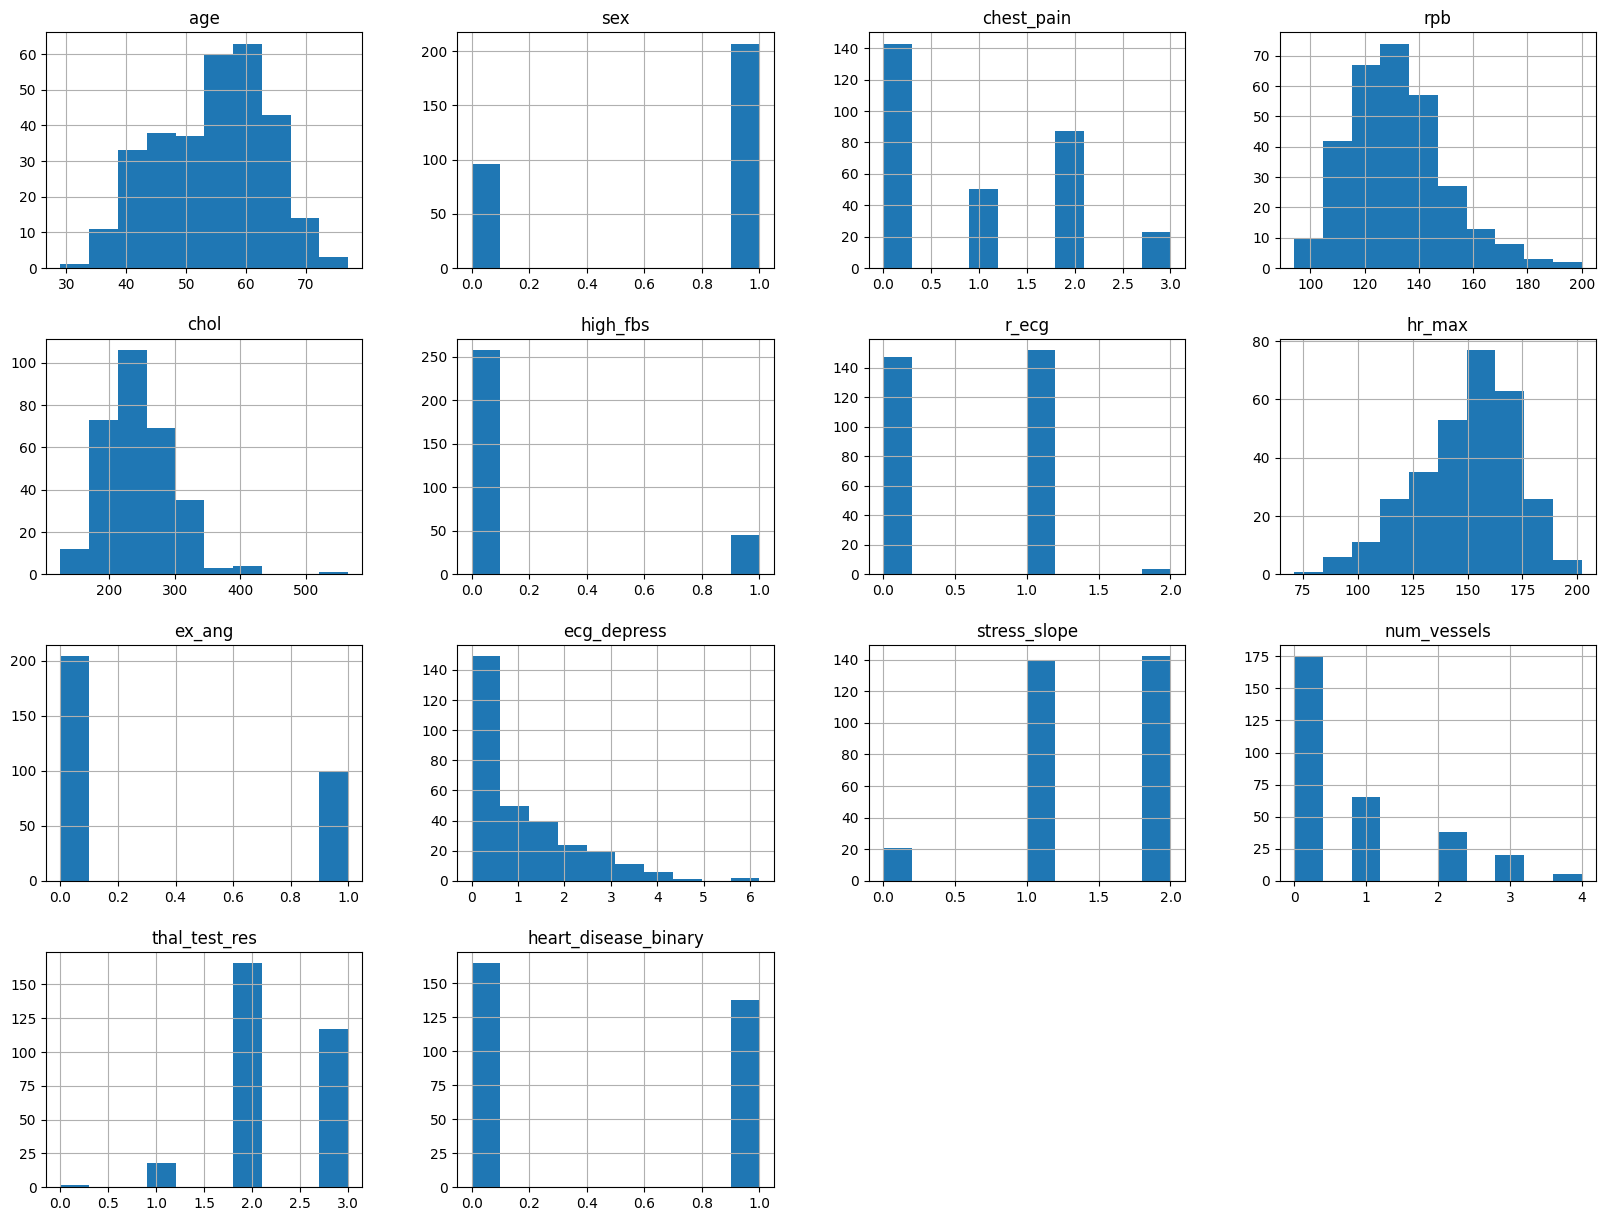

In [130]:
data.hist(figsize=(20,15))
plt.show()


*   age: gradient
*   sex: binary
*   chest pain: limited selection
*   rpb: gradient
*   chol: gradient
*   high fbs: binary
*   r_ecg: limited selection
*   hr_max: gradient
*   ex_ang: binary
*   ecg_depress: gradient
*   stress_slope: limited selection
*   num_vessels: limited selection
*   thal_test_res: limited selection
*   heart_disease_binary: binary


### We also want to make sure we are dealing with a balanced dataset. In this case, we want to confirm whether or not we have an equitable number of  sick and healthy individuals to ensure that our classifier will have a sufficiently balanced dataset to adequately classify the two. Plot a histogram specifically of the heart_disease target, and conduct a count of the number of diseased and healthy individuals and report on the results:

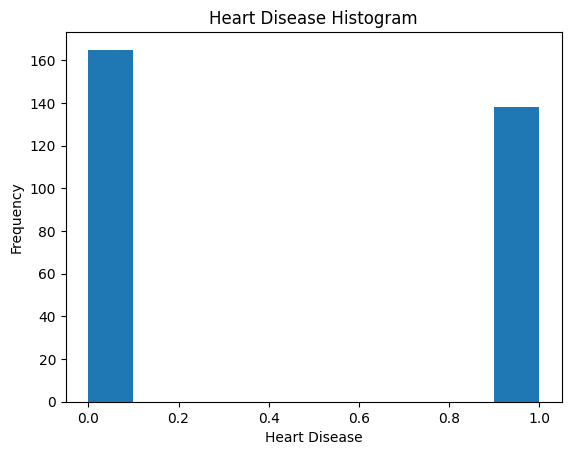

,count
heart_disease_binary,
0,165
1,138


In [131]:
plt.hist(data['heart_disease_binary'])
plt.title('Heart Disease Histogram')
plt.xlabel('Heart Disease')
plt.ylabel('Frequency')
plt.show()
data['heart_disease_binary'].value_counts()

The data is moderately balanced, although we have around 27 more healthy individuals than diseased.

### Now that we have our dataframe prepared let's start analyzing our data. For this next question let's look at the correlations of our variables to our target value. First, map out the correlations between the values, and then discuss the relationships you observe. Do some research on the variables to understand why they may relate to the observed corellations. Intuitively, why do you think some variables correlate more highly than others (hint: one possible approach you can use the sns heatmap function to map the corr() method)?

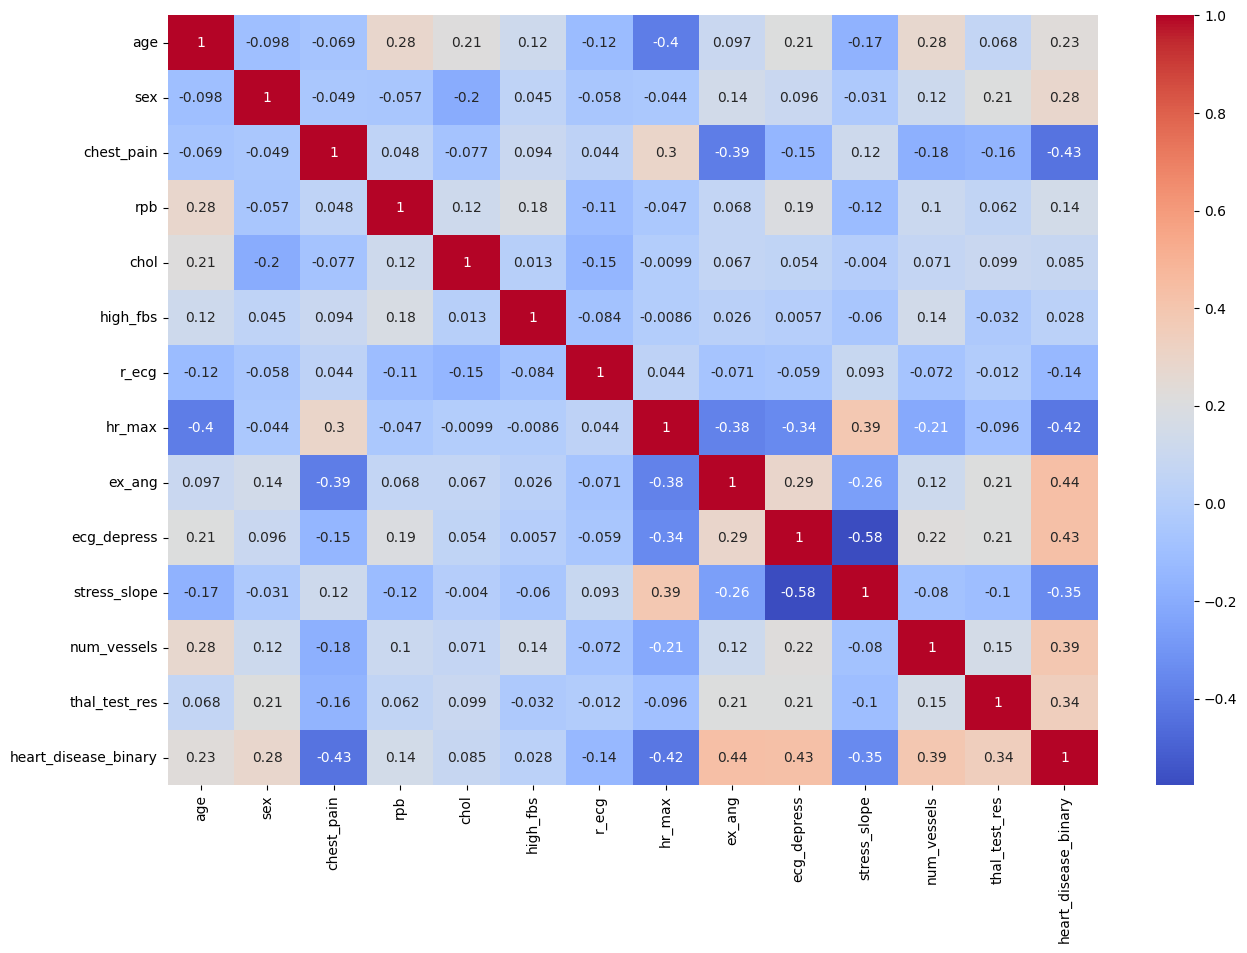

In [132]:
corr = data.corr()
plt.figure(figsize=(15,10))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

Heart disease correlates most with whether or not the patient has exercise-induced angina (ex_ang), depression of the ST segment on ECG during exercise compared to rest (ecg-depress), number of major vessels showing good blood flow during fluoroscopy (num_vessls), and thallium stress test result (thal_test_res).

Upon further research, exercise-induced angina is chest pain, and a symptom of heart disease. It makes sense that this correlates with the target. Depression of the ST segment on ECG during exercise compared to rest is also a sign of heart disease, in addition to the vessels variable. Since these factors are partially used to signify/diagnose heart disease, it makes sense they there is higher correlation than with the rest of the variables. The thallium stress test helps determine how blood is flowing into the heart muscle and how it functions -- so it can be used to help determine heart disease too, explaining the correlation.

## Part 2. Prepare the 'Raw' Data and run a KNN Model

Before running our various learning methods, we need to do some additional prep to finalize our data. Specifically you'll have to cut the classification target from the data that will be used to classify, and then you'll have to divide the dataset into training and testing cohorts.

Specifically, we're going to ask you to prepare 2 batches of data: 1. Will simply be the raw numeric data that hasn't gone through any additional pre-processing. The other, will be data that you pipeline using your own selected methods. We will then feed both of these datasets into a classifier to showcase just how important this step can be!

### Save the label column as a separate array and then drop it from the dataframe.

In [133]:
label = data['heart_disease_binary']
data = data.drop('heart_disease_binary',axis=1)

### First Create your 'Raw' unprocessed training data by dividing your dataframe into training and testing cohorts, with your training cohort consisting of 70% of your total dataframe (hint: use the train_test_split() method) Output the resulting shapes of your training and testing samples to confirm that your split was successful.

In [134]:
X_train, X_test, y_train, y_test = train_test_split(data, label, test_size = 0.3, random_state = 42)

In [135]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(212, 13)
(91, 13)
(212,)
(91,)


### We'll explore how not processing your data can impact model performance by using the K-Nearest Neighbor classifier. One thing to note was because KNN's rely on Euclidean distance, they are highly sensitive to the relative magnitude of different features. Let's see that in action! Implement a K-Nearest Neighbor algorithm on our raw data and report the results. For this initial implementation simply use the **default** settings. Refer to the [KNN Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) for details on implementation. Report on the accuracy of the resulting model.

In [136]:
neigh1 = KNeighborsClassifier()
neigh1.fit(X_train, y_train)
y_pred = neigh1.predict(X_test)
print(metrics.accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))

0.6593406593406593
0.631578947368421
0.5853658536585366
0.6075949367088608


We have an accuracy score of about 66%.

### Now implement a pipeline of your choice. You can opt to handle categoricals however you wish, however please scale your numeric features using standard scaler. Use the fit_transform() to fit this pipeline to your training data. and then transform() to apply that pipeline to your test data

Hint:
1. Create separate pipelines for numeric and categorical features with Pipeline() and then combining them with ColumnTransformer()
2. First, fit the full pipeline with the training data. Then, apply it to the test data as well.

### Pipeline:

In [137]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer

In [138]:
# Create pipelines
numerical_features = ['age','rpb','chol','hr_max','ecg_depress']
categorical_features = ['sex','chest_pain','high_fbs','r_ecg','ex_ang','stress_slope','num_vessels','thal_test_res']

numerical_pipeline = Pipeline([('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('onehot', OneHotEncoder())])
combined_pipeline = ColumnTransformer([('num',numerical_pipeline,numerical_features),
                                      ('cat',categorical_pipeline,categorical_features)])

In [139]:
# Pipeline the training and test data
combined_pipeline.fit_transform(X_train,y_train)
X_train_processed = combined_pipeline.transform(X_train)
X_test_processed = combined_pipeline.transform(X_test)

### Now retrain your model and compare the accuracy metrics (Accuracy, Precision, Recall, F1 Score) with the raw and pipelined data.

In [140]:
# KNN
neigh2 = KNeighborsClassifier()
neigh2.fit(X_train_processed, y_train)
y_pred = neigh2.predict(X_test_processed)
print(metrics.accuracy_score(y_test,y_pred))

0.8571428571428571


In [141]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# Report Metrics
print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))

0.8571428571428571
0.8333333333333334
0.8536585365853658
0.8433734939759037


Overall, the accuracy score was highest, with the model predicting around 86% of the instances correct.

The precision score shows that many of the model's predicted positives were true positives. Even though it is the lowest at around 83%, it is still fairly high. Less false positives.

The recall score shows that it predicted 85% of the actual positives correctly. Less false negatives (true positives that were predicted wrong).

The F1 score is high, at around 84%, so the model balances its positive predictions rather than having a lot of false positives or false negatives.

As compared to the raw data, the 4 metrics were all higher with the pipelined data, by around 20-25%.

### Parameter Optimization.  The KNN Algorithm includes an n_neighbors attribute that specifies how many neighbors to use when developing the cluster. (The default value is 5, which is what your previous model used.) Lets now try n values of: 1, 2, 3, 5, 7, 9, 10, 20, and 50. Run your model for each value and report the accuracy for each. (HINT leverage python's ability to loop to run through the array and generate results without needing to manually code each iteration).

In [142]:
values = [1,2,3,4,5,7,9,10,20,50]
for value in values:
  neigh = KNeighborsClassifier(n_neighbors=value)
  neigh.fit(X_train_processed, y_train)
  y_pred = neigh.predict(X_test_processed)
  print(f"For {value} nearest neighbors, the accuracy score is: {accuracy_score(y_test,y_pred)}")


For 1 nearest neighbors, the accuracy score is: 0.7692307692307693
For 2 nearest neighbors, the accuracy score is: 0.8021978021978022
For 3 nearest neighbors, the accuracy score is: 0.8351648351648352
For 4 nearest neighbors, the accuracy score is: 0.8791208791208791
For 5 nearest neighbors, the accuracy score is: 0.8571428571428571
For 7 nearest neighbors, the accuracy score is: 0.8901098901098901
For 9 nearest neighbors, the accuracy score is: 0.8461538461538461
For 10 nearest neighbors, the accuracy score is: 0.8461538461538461
For 20 nearest neighbors, the accuracy score is: 0.8791208791208791
For 50 nearest neighbors, the accuracy score is: 0.8461538461538461


## Part 3. Additional Learning Methods

So we have a model that seems to work well. But let's see if we can do better! To do so we'll employ multiple learning methods and compare result.

### Linear Decision Boundary Methods

### Logistic Regression

Let's now try another classifier,one that's well known for handling linear models: Logistic Regression. Logistic regression is a statistical model that in its basic form uses a logistic function to model a binary dependent variable.

### Implement a Logistical Regression Classifier. Review the [Logistical Regression Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) for how to implement the model.

### Report metrics for:
1.   Accuracy
2.   Precision
3.   Recall
4.   F1 Score



In [143]:
# Logistic Regression
clf = LogisticRegression(random_state=0).fit(X_train_processed, y_train)
y_pred = clf.predict(X_test_processed)

print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))

0.8571428571428571
0.868421052631579
0.8048780487804879
0.8354430379746836


### Discuss what each measure is reporting, why they are different, and why are each of these measures is significant. Explore why we might choose to evaluate the performance of differing models differently based on these factors. Try to give some specific examples of scenarios in which you might value one of these measures over the others.

Accuracy: Overall, the model predicts around 86% of the instances correct. This is the true positives + true negatives / all of the instances. In this case, we are treating all predictions equally and not considering imbalance, which is why it differs. This matters in judging overall performance, but it is most useful for balanced data. For example, if we have an even distribution of the classes (100 in each), this is a good measure to use.

Precision: The precision score is around 87%.This is the TP/(TP+FP). In other words, it shows that many of the model's predicted positives were true positives. This differs from the accuracy slightly since it does not take negatives into account. As a whole, there were less false alarms and the model is conservative and careful about labelling positives. This would be useful in a case where false positives are important and you want to be more conservative in your predictions. For example, a bank predicting who should be eligible for a loan. Here, you want to err on the side of caution that the candidate is a responsible match.

Recall: The recall score shows that it predicted 80% of the actual positives correctly. It is calculated as TP/(TP+FN). This metric differs from the others since we are taking into account just the actual positives in the data. In a situation where it is costly to miss positives and you want to be more liberal this is useful. For example, if detecting spam, it is more harmful to miss a spam email than flag a normal email as spam.

F1 Score: The F1 score is high, at around 84%. This metric is a combination of precision and recall, so it is lower than precision since it is brought down by the recall value. It gives us an idea of our balance between precision and recall. This would help when you have imbalanced datasets. For example, if a disease is not very common you want to ensure you do not miss positives (false negatives) or negatives (false positives) and you might not have a lot of data. Therefore, F1 would help balance both metrics.

### Let's tweak a few settings. First let's set your solver to 'sag' (Stochastic Average Gradient), your max_iter= 10, and set penalty = None and rerun your model. Let's see how your results change!

In [144]:
clf = LogisticRegression(solver="sag", max_iter=10, penalty = None).fit(X_train_processed, y_train)
y_pred = clf.predict(X_test_processed)

print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))

0.8681318681318682
0.8717948717948718
0.8292682926829268
0.85


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


### Did you notice that when you ran the previous model you got the following warning: "ConvergenceWarning: The max_iter was reached which means the coef_ did not converge". Check the documentation and see if you can implement a fix for this problem, and again report your results.

In [145]:
clf = LogisticRegression(solver="sag", max_iter=10000, penalty = None).fit(X_train_processed, y_train)
y_pred = clf.predict(X_test_processed)

print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))

0.8351648351648352
0.825
0.8048780487804879
0.8148148148148148


### Explain what you changed, and why do you think that may have altered the outcome.

When I changed max iter to 10000, the problem was fixed and the model converged. In the previous example, the gradient descent did not converge to a coefficient in just 10 iterations. I think it converged with more iterations possible since it needed more steps to get to the best coefficients for whatever step size we were using.

### Rerun your logistic classifier, but modify the penalty = 'l1', solver='liblinear' and again report the results.

In [146]:
clf = LogisticRegression(solver="liblinear", max_iter=10000, penalty = 'l1').fit(X_train_processed, y_train)
y_pred = clf.predict(X_test_processed)

print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))

0.8571428571428571
0.868421052631579
0.8048780487804879
0.8354430379746836


### Explain what the two solver approaches are, and why liblinear may have produced an improved outcome (but not always, and it's ok if your results show otherwise!).

SAG: This solver using stochastic average gradient descent. In comparison to normal gradient descent, SAG uses running averages of gradients through mini-batches, speeding up the process a bit. It is more sensitive to noise and not as aggressive in making some coefficients 0. We also used L2 regularization when we used SAG (that minimizes coefficients but does not zero them), since that is the defaulty penalty.

Liblinear: This applies L1 regularization (in the way we used it) and is optimizing one parameter at a time, zeroing out some coefficients eventually (removing features).

Liblinear might be better if you want to zero out irrelevant features. If we have a lot of features and/or noise in our data, liblinear could perform better.

### SVM (Support Vector Machine)

A Support Vector Machine (SVM) is a discriminative classifier formally defined by a separating hyperplane. In other words, given labeled training data (supervised learning), the algorithm outputs an optimal hyperplane which categorizes new examples. In two dimentional space this hyperplane is a line dividing a plane in two parts where in each class lay in either side.

More explanation here: https://en.wikipedia.org/wiki/Support_vector_machine.

For the sake of this project, you can regard it as a type of classifier.

### Implement a Support Vector Machine classifier on your pipelined data. Review the [SVM Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) for how to implement a model. For this implementation you can simply use the default settings, but set probability = True.

In [147]:
clf = SVC(probability= True)
clf.fit(X_train_processed,y_train)
y_pred = clf.predict(X_test_processed)

### Report the accuracy, precision, recall, F1 Score, of your model, but in addition, plot a Confusion Matrix of your model's performance

recommend using `from sklearn.metrics import ConfusionMatrixDisplay` for this one!


In [148]:
# Report Metrics
print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))

0.8791208791208791
0.8571428571428571
0.8780487804878049
0.8674698795180723


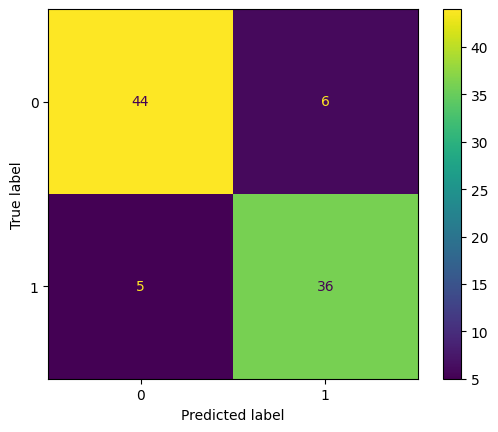

In [149]:
# Confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test,y_pred,labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=clf.classes_)
disp.plot()
plt.show()


### Plot a Receiver Operating Characteristic curve, or ROC curve, and describe what it is and what the results indicate

recommend using the `metrics.roc_curve` `metrics.auc` and `metrics.RocCurveDisplay` for this one!

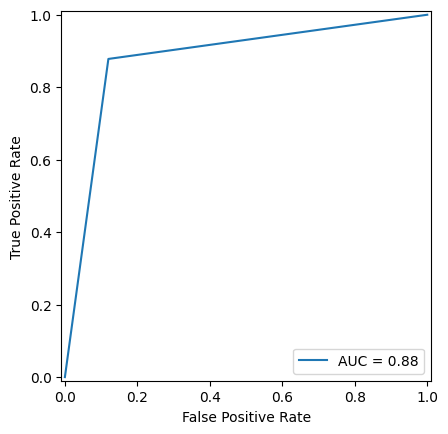

In [150]:
from multiprocessing.pool import IMapUnorderedIterator
# ROC
fpr, tpr, thresholds = metrics.roc_curve(y_test,y_pred)
roc_auc = metrics.auc(fpr,tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
display.plot()
plt.show()

An ROC curve helps visualize the tradeoffs in our predictions. We plot the false positive rate against the true positive rate and map the tradeoff. The area under the ROC curve, the AUC, helps us see the overall performance of the classifier. The performance calculated over all possible thresholds is the AUC. The area tells us how useful the classifier is, and the closer it is to 1 the better. Therefore, our model is performing fairly well (AUC = 0.88).

### Rerun your SVM, but now modify your model parameter kernel to equal 'linear'. Again report your Accuracy, Precision, Recall, F1 scores, and Confusion matrix and plot the new ROC curve.  

In [151]:
# Metrics
clf = SVC(probability=True, kernel='linear')
clf.fit(X_train_processed,y_train)
y_pred = clf.predict(X_test_processed)

print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))

0.8351648351648352
0.825
0.8048780487804879
0.8148148148148148


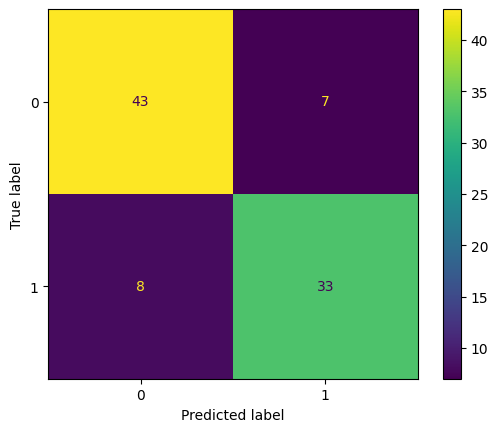

In [152]:
# Confusion Matrix
cm = confusion_matrix(y_test,y_pred,labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=clf.classes_)
disp.plot()
plt.show()

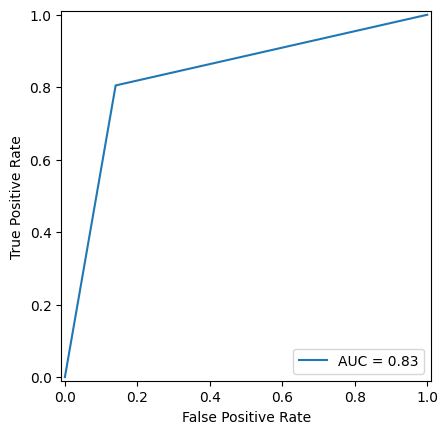

In [153]:
# ROC
fpr, tpr, thresholds = metrics.roc_curve(y_test,y_pred)
roc_auc = metrics.auc(fpr,tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
display.plot()
plt.show()

### Explain the what the new results you've achieved mean. Read the documentation to understand what you've changed about your model and explain why changing that input parameter might impact the results in the manner you've observed.

The value of each metric went slightly down. We can also see in the confusion matrix that there are a few more false positives+negatives and less true positives+negatives than before. We see a lower AUC (0.88 vs 0.83). And the ROC curve is hugging the top left corner of the graph (the ideal spot) less so now.

We changed the kernel from rbf to linear. The difference is that rbf creates more complex decision boundaries while linear creates linear decision boundaries. Since RBF allows for more complex decision boundaries, it makes sense that it resulted in high accuracy, precision, recall, and F1 score. The model could capture more intricate patterns in the data, allowing for better predictions.

### Both logistic regression and linear SVM are trying to classify data points using a linear decision boundary, then what’s the difference between their ways to find this boundary?

What differs between this model is what they are trying to minimize/maximize when finding the linear decision boundary. Logistic regression finds the probability of a label being 1 and then assigns it the class based on that (if it is above 0.5, it is 1, if below 0). It tries to minimize log-loss. For linear SVM, it is finding a hyperplane that maximizes between the closest data points of each class. In other words, it is maximizing separation.

### Decision Trees

Create both a Decision Tree and a KNN and fit them onto your fully preprocessed data, then calculate an accuracy score for both (https://scikit-learn.org/stable/api/sklearn.tree.html).

### What are Decision Trees?

Decision Trees are a non-parametric supervised learning methods used for classification and regression. The goal is to split data into branches based on feature conditions, forming a tree-like structure where each internal node represents a decision, and each branch represents an outcome.

Compared to KNN, decision trees is less influenced by the high dimensionality of the data, and can make the model output more predicable.

For more explanation, see here: https://en.wikipedia.org/wiki/Decision_tree. For the sake of this project, you can regard it as a type of classifier.

In [154]:
from sklearn.tree import DecisionTreeClassifier
# Decision Tree
clf1 = DecisionTreeClassifier()
clf1.fit(X_train_processed,y_train)
y_pred1 = clf1.predict(X_test_processed)

# KNN
clf2 = KNeighborsClassifier()
clf2.fit(X_train_processed,y_train)
y_pred2 = clf2.predict(X_test_processed)

In [155]:
# Decision Tree Accuracy
print(accuracy_score(y_test,y_pred1))

# KNN Accuracy
print(accuracy_score(y_test,y_pred2))


0.8131868131868132
0.8571428571428571


#### Categorical Preprocessing Only

Create a new preprocessing pipeline which ONLY preprocesses categorical values (leaving scalar variables in the data as they were originally, ie. no StandardScaler).   
Process your data with this new pipeline, fit a decision tree and a KNN once more and report a new accuracy score for each.   

Hint: Ensure that remainder = 'passthrough' in your ColumnTransformer to ensure scalar values are not dropped!    

In [156]:
# Categorical Preprocessing Only
categorical_features = ['sex','chest_pain','high_fbs','r_ecg','ex_ang','stress_slope','num_vessels','thal_test_res']

categorical_pipeline = Pipeline([('onehot', OneHotEncoder())])

combined_pipeline = ColumnTransformer([('cat',categorical_pipeline,categorical_features)],
                                      remainder='passthrough')
combined_pipeline.fit(X_train,y_train)
X_train_processed = combined_pipeline.transform(X_train)
X_test_processed = combined_pipeline.transform(X_test)

In [157]:
# Fit Decision Tree
clf1 = DecisionTreeClassifier()
clf1.fit(X_train_processed,y_train)
y_pred1 = clf1.predict(X_test_processed)

# Fit KNN
clf2 = KNeighborsClassifier()
clf2.fit(X_train_processed,y_train)
y_pred2 = clf2.predict(X_test_processed)


In [158]:
# Decision Tree Accuracy
print(accuracy_score(y_test,y_pred1))

# KNN Accuracy
print(accuracy_score(y_test,y_pred2))



0.8021978021978022
0.6593406593406593


#### Explain the difference in accuracy loss in Decision Trees vs KNNs when Standardization was removed.

When we remove standardization, the accuracy of DT went up by 0.03. More noticeably, the accuracy for KNNs went down by 0.2, a much bigger difference. This emphasizes how standardization is important for KNNs. Since we are using Euclidean distance (a numerical calculation) to make our predictions, units can affect our model. As mentioned earlier, KNNs are very sensitive to the relative magnitude of different features. By standardizing numerical features too, features with larger units and features with smaller units are considered equally as important. With DT, we are not really doing mathematical distance calculations, so it does not prove to be as important to standardize the data.

# Printing Jupyter notebook to PDF (Google Colab Only, Optional)

It may take a few minutes to run

In [159]:
def colab2pdf():
  ENABLE=True # @param {type:"boolean"}
  if ENABLE:
    !apt-get install librsvg2-bin
    import os, datetime, json, locale, pathlib, urllib, requests, werkzeug, nbformat, google, yaml, warnings
    locale.setlocale(locale.LC_ALL, 'en_US.UTF-8')
    NAME = pathlib.Path(werkzeug.utils.secure_filename(urllib.parse.unquote(requests.get(f"http://{os.environ['COLAB_JUPYTER_IP']}:{os.environ['KMP_TARGET_PORT']}/api/sessions").json()[0]["name"])))
    TEMP = pathlib.Path("/content/pdfs") / f"{datetime.datetime.now().strftime('%Y%m%d_%H%M%S')}_{NAME.stem}"; TEMP.mkdir(parents=True, exist_ok=True)
    NB = [cell for cell in nbformat.reads(json.dumps(google.colab._message.blocking_request("get_ipynb", timeout_sec=600)["ipynb"]), as_version=4).cells if "--Colab2PDF" not in cell.source]
    warnings.filterwarnings('ignore', category=nbformat.validator.MissingIDFieldWarning)
    with (TEMP / f"{NAME.stem}.ipynb").open("w", encoding="utf-8") as nb_copy: nbformat.write(nbformat.v4.new_notebook(cells=NB or [nbformat.v4.new_code_cell("#")]), nb_copy)
  if not pathlib.Path("/usr/local/bin/quarto").exists():
    !wget -q "https://quarto.org/download/latest/quarto-linux-amd64.deb" -P {TEMP} && dpkg -i {TEMP}/quarto-linux-amd64.deb > /dev/null && quarto install tinytex --update-path --quiet
    with (TEMP / "config.yml").open("w", encoding="utf-8") as file: yaml.dump({'include-in-header': [{"text": r"\usepackage{fvextra}\DefineVerbatimEnvironment{Highlighting}{Verbatim}{breaksymbolleft={},showspaces=false,showtabs=false,breaklines,breakanywhere,commandchars=\\\{\}}"}],'include-before-body': [{"text": r"\DefineVerbatimEnvironment{verbatim}{Verbatim}{breaksymbolleft={},showspaces=false,showtabs=false,breaklines}"}]}, file)
    !quarto render {TEMP}/{NAME.stem}.ipynb --metadata-file={TEMP}/config.yml --to pdf -M latex-auto-install -M margin-top=1in -M margin-bottom=1in -M margin-left=1in -M margin-right=1in --quiet
    google.colab.files.download(str(TEMP / f"{NAME.stem}.pdf"))
colab2pdf()

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  librsvg2-bin
0 upgraded, 1 newly installed, 0 to remove and 21 not upgraded.
Need to get 1,871 kB of archives.
After this operation, 6,019 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 librsvg2-bin amd64 2.52.5+dfsg-3ubuntu0.2 [1,871 kB]
Fetched 1,871 kB in 0s (12.4 MB/s)
Selecting previously unselected package librsvg2-bin.
(Reading database ... 124926 files and directories currently installed.)
Preparing to unpack .../librsvg2-bin_2.52.5+dfsg-3ubuntu0.2_amd64.deb ...
Unpacking librsvg2-bin (2.52.5+dfsg-3ubuntu0.2) ...
Setting up librsvg2-bin (2.52.5+dfsg-3ubuntu0.2) ...
Processing triggers for man-db (2.10.2-1) ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>